# 📊 Biais et approfondissement

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 14h15** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Détecter les sur- et sous-représentations par rapport à une référence
- Quantifier les disparités d'une décision algorithmique avec Fairlearn
- Identifier les corrélations induites et les limites de l'analyse

In [1]:
%pip install -q fairlearn
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")


✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [2]:
# Secteur traité : Crédit Azur (banque) — autres choix : "commerce", "hotellerie"
SECTEUR = "banque"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Crédit Azur · 20477 lignes, 20 colonnes


In [3]:
from fairlearn.metrics import (MetricFrame, selection_rate, count, true_positive_rate,
                               demographic_parity_difference, demographic_parity_ratio)
df = nettoyage_minimal(brut, cfg)
for col in cfg["sensibles"]:
    df[col] = df[col].fillna("inconnu")
y = df[cfg["decision"]]
print("Décision étudiée :", cfg["decision_label"], f"· taux global {y.mean():.1%}")

Décision étudiée : crédit accordé · taux global 64.0%


## 1. La représentativité
Sur les **clients uniques**, comparez la part de chaque modalité à la population de référence (`reference()`). Signalez les ratios inférieurs à 0,8 ou supérieurs à 1,25.

In [4]:
# Clients uniques : une ligne par client (première demande observée)
clients = df.drop_duplicates("client_id")
print(len(clients), "clients uniques pour", len(df), "demandes")
ref = reference()

lignes = []
for col in cfg["sensibles"]:
    obs = clients[col].value_counts(normalize=True).rename("part_observee").reset_index()
    obs.columns = ["modalite", "part_observee"]
    obs["variable"] = col
    lignes.append(obs)
representativite = pd.concat(lignes).merge(ref, on=["variable", "modalite"], how="left")
representativite["ratio"] = representativite["part_observee"] / representativite["part_reference"]
representativite["statut"] = np.select(
    [representativite["ratio"].isna(), representativite["ratio"] < 0.8, representativite["ratio"] > 1.25],
    ["sans référence", "sous-représenté", "sur-représenté"], default="conforme")
representativite = representativite[["variable", "modalite", "part_observee", "part_reference", "ratio", "statut"]]
display(representativite.round(3).sort_values(["variable", "ratio"]).reset_index(drop=True))
print("Groupes signalés :")
display(representativite[representativite["statut"].isin(["sous-représenté", "sur-représenté"])].round(2))

11170 clients uniques pour 20384 demandes


,variable,modalite,part_observee,part_reference,ratio,statut
0,genre,F,0.428,0.52,0.824,conforme
1,genre,H,0.572,0.48,1.191,conforme
2,region,Outre-mer,0.011,0.03,0.352,sous-représenté
3,region,Nord-Est,0.234,0.24,0.974,conforme
4,region,Île-de-France,0.186,0.19,0.981,conforme
5,region,Sud-Ouest,0.139,0.14,0.992,conforme
6,region,Ouest,0.210,0.21,0.998,conforme
7,region,Sud-Est,0.221,0.19,1.163,conforme
8,tranche_age,65+,0.069,0.26,0.264,sous-représenté
9,tranche_age,55-64,0.130,0.16,0.811,conforme


Groupes signalés :


,variable,modalite,part_observee,part_reference,ratio,statut
0,tranche_age,25-34,0.26,0.15,1.73,sur-représenté
1,tranche_age,35-44,0.25,0.16,1.59,sur-représenté
5,tranche_age,65+,0.07,0.26,0.26,sous-représenté
13,region,Outre-mer,0.01,0.03,0.35,sous-représenté


**Lecture de la représentativité** (clients uniques, 11 170 clients) :
- **65 ans et plus : sous-représentés** (6,9 % des clients contre 26 % de la population, ratio 0,26), mais leur taux d'accord est bon (81 %) : le problème est en amont de la décision (peu de demandes).
- **25-34 ans (ratio 1,73) et 35-44 ans (1,59) : sur-représentés**, ce qui est cohérent avec une clientèle d'emprunteurs.
- **Outre-mer : sous-représenté** (1,1 % des clients contre 3 %, ratio 0,35), sur un effectif faible.
- Genre et les autres régions sont conformes ; les femmes sont à la limite basse (0,82). Les 18-24 ans sont conformes (0,91).
- **Réserve :** la référence est la population nationale, pas la population qui demande un crédit ; le ratio des 65 ans et plus en est probablement exagéré.

## 2. La parité de la décision
Pour chaque variable sensible, calculez avec `MetricFrame` le taux de décision favorable et l'effectif par groupe, puis l'écart et le ratio de parité démographique.

In [5]:
synthese = []
tables = {}
for col in cfg["sensibles"]:
    mf = MetricFrame(metrics={"taux": selection_rate, "effectif": count},
                     y_true=y, y_pred=y, sensitive_features=df[col])   # MetricFrame : taux de décision favorable et effectif par groupe
    display(mf.by_group.assign(effectif=lambda d: d["effectif"].astype(int)).round(3))
    tables[col] = mf.by_group
    synthese.append({"variable": col,
                     "ecart": demographic_parity_difference(y, y, sensitive_features=df[col]),
                     "ratio": demographic_parity_ratio(y, y, sensitive_features=df[col])})
synthese = pd.DataFrame(synthese)
synthese["alerte (< 0,8)"] = np.where(synthese["ratio"] < 0.8, "⚠ oui", "non")
synthese.round(3)

,taux,effectif
tranche_age,,
18-24,0.183,1788
25-34,0.440,5299
35-44,0.689,5228
45-54,0.829,4002
55-64,0.873,2636
65+,0.813,1431


,taux,effectif
genre,,
F,0.596,8731
H,0.672,11653


,taux,effectif
region,,
Nord-Est,0.617,4735
Ouest,0.626,4321
Outre-mer,0.575,207
Sud-Est,0.625,4499
Sud-Ouest,0.619,2825
Île-de-France,0.721,3797


,variable,ecart,ratio,"alerte (< 0,8)"
0,tranche_age,0.690,0.210,⚠ oui
1,genre,0.076,0.887,non
2,region,0.146,0.798,⚠ oui


**Conclusion par variable sensible**
- **Âge : disparité forte.** Taux d'accord de 18 % (18-24 ans) à 87 % (55-64 ans), écart de 69 points, **ratio de parité 0,21**, très en dessous du seuil de 0,8.
- **Genre : sous le seuil d'alerte mais perceptible.** Femmes 60 % contre hommes 67 %, ratio 0,89 (au-dessus de 0,8), écart de 7,6 points.
- **Région : alerte limite, fragile.** Ratio 0,798, juste sous 0,8, tiré par l'Île-de-France (72 %) et par l'Outre-mer (57,5 % sur seulement 207 demandes) ; les autres régions sont à 62 %. À confirmer avant de conclure.

## 3. Les croisements
Un biais peut se cacher dans un croisement. Calculez le taux par combinaison de deux variables sensibles.

genre,F,H
tranche_age,,
18-24,0.164,0.195
25-34,0.386,0.484
35-44,0.636,0.726
45-54,0.787,0.858
55-64,0.844,0.896
65+,0.771,0.848


genre,F,H
tranche_age,,
18-24,713,1075
25-34,2354,2945
35-44,2190,3038
45-54,1670,2332
55-64,1158,1478
65+,646,785


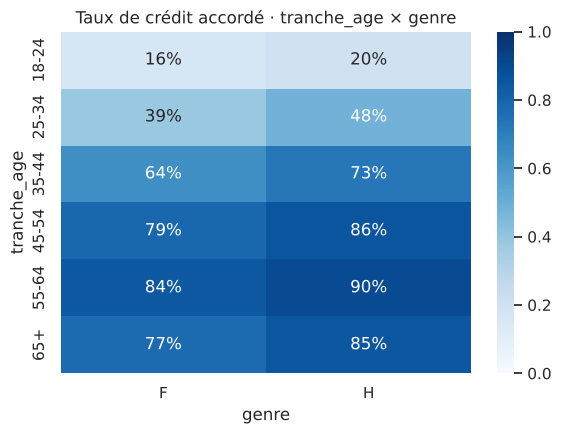

Écart de parité sur le croisement : 73.2% (plus faible : ('18-24', 'F') · plus forte : ('55-64', 'H'))
Ratio F / H par tranche d'âge :
tranche_age
18-24    0.84
25-34    0.80
35-44    0.88
45-54    0.92
55-64    0.94
65+      0.91


In [6]:
v1, v2 = cfg["sensibles"][0], cfg["sensibles"][1]
mf2 = MetricFrame(metrics={"taux": selection_rate, "effectif": count}, y_true=y, y_pred=y,
                  sensitive_features=df[[v1, v2]])
croise = mf2.by_group["taux"].unstack(v2)
effectifs = mf2.by_group["effectif"].unstack(v2)
display(croise.round(3)); display(effectifs.astype(int))
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(croise, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title(f"Taux de crédit accordé · {v1} × {v2}"); plt.tight_layout(); plt.show()
print(f"Écart de parité sur le croisement : {mf2.by_group['taux'].max() - mf2.by_group['taux'].min():.1%} "
      f"(plus faible : {mf2.by_group['taux'].idxmin()} · plus forte : {mf2.by_group['taux'].idxmax()})")
# genre : écart au sein de chaque tranche d'âge
print("Ratio F / H par tranche d'âge :"); print((croise["F"] / croise["H"]).round(2).to_string() if {"F", "H"} <= set(croise.columns) else "")

**Lecture du croisement âge × genre** : le croisement amplifie l'écart d'âge. Le taux le plus bas concerne les **femmes de 18-24 ans (16,4 %)**, le plus haut les **hommes de 55-64 ans (89,6 %)**, soit 73 points d'écart. L'écart femmes/hommes est le plus marqué chez les jeunes (ratio F/H de 0,84 à 18-24 ans et de 0,80 à 25-34 ans) et se resserre ensuite (0,94 à 55-64 ans) : le genre pèse davantage là où l'âge pénalise déjà.

## 4. Les corrélations induites
La disparité la plus forte persiste-t-elle **à segment égal** ? Comparez les taux par variable sensible à l'intérieur de chaque segment métier.

In [7]:
var = synthese.sort_values("ratio")["variable"].iloc[0]
seg = cfg["segment"]
print("Variable la plus disparate :", var)

# Taux par groupe à l'intérieur de chaque type de crédit
par_seg = df.pivot_table(index=var, columns=seg, values=cfg["decision"], aggfunc="mean")
par_seg["tous types"] = df.groupby(var)[cfg["decision"]].mean()
display(par_seg.round(3))
rat = par_seg.min() / par_seg.max()
print("Ratio de parité (plus faible ÷ plus fort) :"); print(rat.round(3).to_string())

# Autres facteurs de risque légitimes : contrat et ancienneté (proxys possibles de l'âge)
print("\nLiaison entre", var, "et le contrat :"); display(pd.crosstab(df[var], df["contrat"], normalize="index").round(3))
print("Ancienneté d'emploi médiane par", var, ":"); print(df.groupby(var)["anciennete_emploi_ans"].median().round(1).to_string())
print("\nTaux d'accord à contrat égal :"); display(df.pivot_table(index=var, columns="contrat", values=cfg["decision"], aggfunc="mean").round(3))

# Modèle logistique : l'écart d'âge persiste-t-il à profil de risque égal ?
import statsmodels.formula.api as smf
d = df.assign(accord=df[cfg["decision"]], anc=df["anciennete_emploi_ans"]).dropna(subset=["revenu_mensuel"])
d["apres"] = (d[cfg["date"]] >= pd.Timestamp(cfg["evenement"][0])).astype(int)
m = smf.logit(f"accord ~ C({var}, Treatment('45-54')) + C(contrat) + taux_endettement + anc + np.log(revenu_mensuel) + C({seg}) + apres",
              data=d).fit(disp=0)
res = pd.DataFrame({"odds ratio": np.exp(m.params), "p": m.pvalues}).round(3)
display(res[res.index.str.contains(var)])

# L'événement a-t-il pénalisé les plus jeunes AU-DELÀ de leur profil de risque ? (interaction jeune × après)
d["jeune"] = (d["tranche_age"] == "18-24").astype(int)
m2 = smf.logit(f"accord ~ jeune * apres + C(contrat) + taux_endettement + anc + np.log(revenu_mensuel) + C({seg})", data=d).fit(disp=0)
res2 = pd.DataFrame({"odds ratio": np.exp(m2.params), "p": m2.pvalues}).round(4)
print("À profil de risque égal (contrat, endettement, ancienneté, revenu, type de crédit) :")
display(res2.loc[["jeune", "apres", "jeune:apres"]])

Variable la plus disparate : tranche_age


type_credit,auto,personnel,renouvelable,travaux,tous types
tranche_age,,,,,
18-24,0.175,0.166,0.161,0.224,0.183
25-34,0.403,0.459,0.426,0.468,0.440
35-44,0.655,0.707,0.695,0.704,0.689
45-54,0.802,0.828,0.838,0.856,0.829
55-64,0.858,0.876,0.881,0.882,0.873
65+,0.810,0.836,0.778,0.814,0.813


Ratio de parité (plus faible ÷ plus fort) :
type_credit
auto            0.204
personnel       0.189
renouvelable    0.183
travaux         0.254
tous types      0.210

Liaison entre tranche_age et le contrat :


contrat,CDD,CDI,indépendant
tranche_age,,,
18-24,0.450,0.438,0.112
25-34,0.158,0.708,0.134
35-44,0.117,0.757,0.126
45-54,0.122,0.743,0.135
55-64,0.120,0.753,0.127
65+,0.122,0.748,0.131


Ancienneté d'emploi médiane par tranche_age :
tranche_age
18-24    0.9
25-34    3.4
35-44    6.4
45-54    9.1
55-64    8.8
65+      9.1

Taux d'accord à contrat égal :


contrat,CDD,CDI,indépendant
tranche_age,,,
18-24,0.112,0.263,0.155
25-34,0.188,0.510,0.365
35-44,0.372,0.752,0.600
45-54,0.585,0.877,0.781
55-64,0.604,0.921,0.839
65+,0.534,0.861,0.802


,odds ratio,p
"C(tranche_age, Treatment('45-54'))[T.18-24]",1.301,0.062
"C(tranche_age, Treatment('45-54'))[T.25-34]",0.961,0.670
"C(tranche_age, Treatment('45-54'))[T.35-44]",0.975,0.777
"C(tranche_age, Treatment('45-54'))[T.55-64]",0.837,0.134
"C(tranche_age, Treatment('45-54'))[T.65+]",0.910,0.492


À profil de risque égal (contrat, endettement, ancienneté, revenu, type de crédit) :


,odds ratio,p
jeune,3.7658,0.0
apres,0.0468,0.0
jeune:apres,0.1421,0.0


**Lecture** : à type de crédit égal, l'écart d'âge ne bouge pas (ratio de parité de 0,18 à 0,25 selon le type de crédit, contre 0,21 au global), et l'âge est indépendant du type de crédit demandé (V de Cramér = 0,014) : **le segment métier n'est pas le proxy**. La disparité passe en revanche par des critères de risque liés à l'âge : 45 % des 18-24 ans sont en CDD (12 % à partir de 35 ans) et leur ancienneté médiane est de 0,9 an (9 ans après 45 ans). À contrat égal l'écart se réduit sans disparaître (en CDI : 26 % d'accord à 18-24 ans contre 88 % à 45-54 ans). Dans le modèle logistique à profil de risque égal (contrat, endettement, ancienneté, revenu, type de crédit, période), l'effet de l'âge seul n'est plus significatif à 5 % (rapports de cotes de 0,84 à 1,30, p ≥ 0,06). **La disparité vient donc surtout de variables qui jouent le rôle de proxys de l'âge (contrat, ancienneté, revenu), pas de l'âge lui-même, mais cela ne suffit pas à expliquer l'effet du score V2 (section 5).** Lecture : un critère de risque légitime explique une partie de l'écart, pas son évolution.

## 5. L'évolution dans le temps
La disparité a-t-elle changé avec l'événement du brief ? Comparez les taux avant et après la date.

taux global         ecart         ratio       
periode           après  avant  après  avant  après  avant
variable                                                  
genre             0.568  0.761  0.071  0.083  0.882  0.895
region            0.568  0.761  0.118  0.178  0.818  0.789
tranche_age       0.568  0.761  0.755  0.579  0.092  0.384

periode,avant,après,variation (pts)
tranche_age,,,
18-24,0.361,0.077,-28.399
25-34,0.603,0.343,-25.978
35-44,0.814,0.615,-19.895
45-54,0.912,0.779,-13.254
55-64,0.940,0.832,-10.777
65+,0.897,0.765,-13.133


Score algorithmique moyen par tranche d'âge :


periode,avant,après
tranche_age,,
18-24,0.535,0.320
25-34,0.672,0.531
35-44,0.773,0.679
45-54,0.833,0.767
55-64,0.855,0.798
65+,0.818,0.761


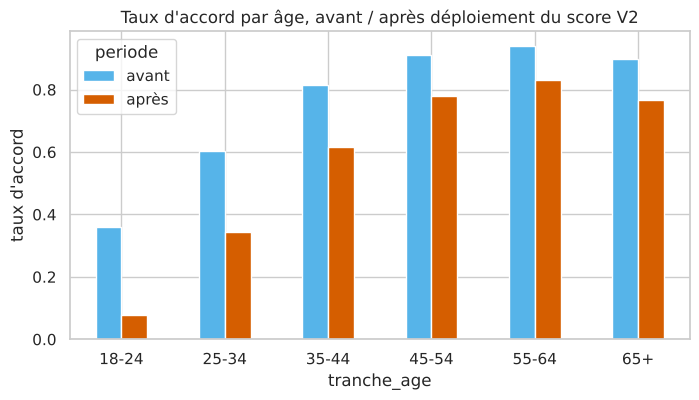

In [8]:
ev = pd.Timestamp(cfg["evenement"][0])
d = df.assign(periode=np.where(df[cfg["date"]] < ev, "avant", "après"))
lignes = []
for col in cfg["sensibles"]:
    for per, sous in d.groupby("periode"):
        lignes.append({"variable": col, "periode": per, "taux global": sous[cfg["decision"]].mean(),
                       "ecart": demographic_parity_difference(sous[cfg["decision"]], sous[cfg["decision"]], sensitive_features=sous[col]),
                       "ratio": demographic_parity_ratio(sous[cfg["decision"]], sous[cfg["decision"]], sensitive_features=sous[col])})
evol = pd.DataFrame(lignes).pivot(index="variable", columns="periode", values=["taux global", "ecart", "ratio"])
display(evol.round(3))

var_age = "tranche_age"
t = d.pivot_table(index=var_age, columns="periode", values=cfg["decision"], aggfunc="mean").loc[["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]][["avant", "après"]]
t["variation (pts)"] = (t["après"] - t["avant"]) * 100
display(t.round(3))
sc = d.pivot_table(index=var_age, columns="periode", values="score_algo", aggfunc="mean").loc[["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]][["avant", "après"]]
print("Score algorithmique moyen par tranche d'âge :"); display(sc.round(3))
from config_projet import PALETTE
ax = t[["avant", "après"]].plot.bar(figsize=(8, 4), color=[PALETTE[4], PALETTE[5]])
ax.set_ylabel("taux d'accord"); ax.set_title("Taux d'accord par âge, avant / après " + cfg["evenement"][1]); plt.xticks(rotation=0); plt.show()

**Lecture de l'évolution** : l'événement a **creusé** la disparité d'âge. Le ratio de parité de l'âge passe de **0,38 avant à 0,09 après** le score V2 (écart de 58 à 76 points). Les 18-24 ans passent de 36 % à 8 % d'accord (−28 points) et les 25-34 ans de 60 % à 34 % (−26 points), contre −11 points pour les 55-64 ans. Le score moyen de ces deux tranches baisse beaucoup plus (18-24 ans : 0,54 → 0,32 ; 65 ans et plus : 0,82 → 0,76). Le genre (ratio 0,90 → 0,88) et la région (0,79 → 0,82) ne bougent presque pas : l'effet est propre à l'âge. Enfin, le modèle à profil de risque égal confirme que ce n'est pas qu'une question de profil : avant V2, un 18-24 ans à profil égal avait un avantage (rapport de cotes ≈ 3,8) ; après, il a un désavantage (≈ 0,54), l'interaction âge × V2 est de 0,14 (p < 0,001). *Modèle descriptif, pas causal : les variables corrélées (ancienneté, contrat) rendent chaque coefficient fragile, mais le basculement est net.*

## 6. L'égalité des chances
Quand le résultat réel est connu, comparez le **taux de vrais positifs** par groupe : parmi ceux pour qui le résultat a été favorable, quelle part avait reçu la décision favorable ?

Résultat connu pour 64.0% des demandes — et pour 100% des crédits accordés contre 0% des refusés.

— tranche_age : TPR par groupe


tranche_age,18-24,25-34,35-44,45-54,55-64,65+
TPR,1.0,1.0,1.0,1.0,1.0,1.0
effectif,327.0,2332.0,3600.0,3316.0,2301.0,1164.0



— genre : TPR par groupe


genre,F,H
TPR,1.0,1.0
effectif,5207.0,7833.0



— region : TPR par groupe


region,Nord-Est,Ouest,Outre-mer,Sud-Est,Sud-Ouest,Île-de-France
TPR,1.0,1.0,1.0,1.0,1.0,1.0
effectif,2921.0,2704.0,119.0,2812.0,1748.0,2736.0


,accord,rembourse,taux d'accord global
tranche_age,,,
18-24,327,0.951,0.183
25-34,2332,0.967,0.440
35-44,3600,0.974,0.689
45-54,3316,0.976,0.829
55-64,2301,0.982,0.873
65+,1164,0.984,0.813


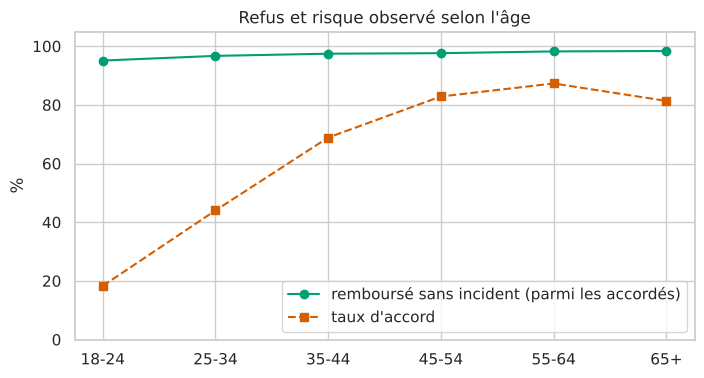

In [9]:
from config_projet import PALETTE
connu = df[cfg["resultat"]].notna()
print(f"Résultat connu pour {connu.mean():.1%} des demandes — et pour {df.loc[df[cfg['decision']] == 1, cfg['resultat']].notna().mean():.0%} "
      f"des crédits accordés contre {df.loc[df[cfg['decision']] == 0, cfg['resultat']].notna().mean():.0%} des refusés.")

# Taux de vrais positifs : parmi les remboursés, quelle part avait reçu la décision favorable ?
for col in cfg["sensibles"]:
    mf = MetricFrame(metrics={"TPR": true_positive_rate, "effectif": count},
                     y_true=df.loc[connu, cfg["resultat"]].astype(int), y_pred=df.loc[connu, cfg["decision"]],
                     sensitive_features=df.loc[connu, col])
    print(f"\n— {col} : TPR par groupe"); display(mf.by_group.round(3).T)

# Ce que la sélection cache : on ne voit jamais ce qu'auraient fait les refusés.
# Contrôle utile : parmi les crédits accordés, le taux de remboursement par groupe.
acc = df[df[cfg["decision"]] == 1]
r = acc.groupby("tranche_age").agg(accord=("credit_accorde", "size"), rembourse=(cfg["resultat"], "mean")).loc[["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]]
r["taux d'accord global"] = df.groupby("tranche_age")[cfg["decision"]].mean().loc[["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]]
display(r.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r.index, r["rembourse"] * 100, "o-", color=PALETTE[2], label="remboursé sans incident (parmi les accordés)")
ax.plot(r.index, r["taux d'accord global"] * 100, "s--", color=PALETTE[5], label="taux d'accord")
ax.set_ylim(0, 105); ax.set_ylabel("%"); ax.legend(); ax.set_title("Refus et risque observé selon l'âge"); plt.show()

**Lecture de l'égalité des chances** : **elle n'est pas mesurable ici**. Le taux de vrais positifs vaut 100 % pour tous les groupes, par construction : le remboursement n'est connu que pour les crédits accordés (100 % des accordés, 0 % des refusés), donc tout client « remboursé » a forcément reçu la décision favorable. C'est le **biais de sélection** de la banque. Le contrôle disponible est le remboursement parmi les accordés : **95,1 % pour les 18-24 ans contre 98,4 % pour les 65 ans et plus**, soit 3 points d'écart pour un taux d'accord qui va de 18 % à 87 %. Les jeunes acceptés remboursent presque aussi bien, ce qui suggère un seuil plus sévère que leur risque observé, mais ce chiffre est biaisé à la baisse (les 327 jeunes acceptés ont passé un filtre sévère) et on ne saura jamais ce qu'auraient fait les refusés.

## 7. Les limites de votre analyse
1. **La référence** : population nationale, approximative (inspirée de l'INSEE), et non la population qui demande un crédit. Le sous-poids des 65 ans et plus (ratio 0,26) en est probablement exagéré. Il faudrait la répartition de la clientèle visée.
2. **Les clients uniques** : un client est compté une fois avec les attributs de sa première demande ; son âge, donc sa tranche, change s'il redemande plus tard.
3. **La sélection** : le remboursement n'est connu que pour les 64 % de crédits accordés. L'égalité des chances ne se calcule pas (TPR = 100 % partout) et le taux de remboursement observé chez les accordés sous-estime le risque réel des jeunes.
4. **Les effectifs** : l'Outre-mer ne compte que 207 demandes (1 % du total) et 327 jeunes de 18-24 ans ont été acceptés : leurs taux sont fragiles, d'où l'alerte « région » à confirmer.
5. **Les manquants** : 2,8 % de revenus manquants, écartés du modèle logistique ; ils paraissent aléatoires (identiques entre canaux) mais on ne peut pas le prouver.
6. **La causalité** : une disparité n'est pas une preuve de discrimination. Le modèle logistique est descriptif, et la comparaison avant/après ne distingue pas le score V2 d'autres changements simultanés (politique d'acceptation, conjoncture). Nous n'avons ni les règles du score V1 et V2, ni l'historique de crédit ou d'incidents des clients.
7. **Le cadre** : l'évaluation de la solvabilité est un usage à haut risque de l'IA Act, et l'âge ou le genre sont des données à manier avec une finalité claire (RGPD) : ces résultats déclenchent une enquête, ils ne concluent pas.

## 💾 Livrable de fin de journée
Votre notebook d'analyse complet, chaque choix justifié dans une cellule markdown, enregistré dans GitHub :
*Fichier › Enregistrer une copie dans GitHub*, message « Jour 1 : analyse et biais ». Envoyez le lien du dépôt au formateur.